# Part A. TF-IDF + KNN

Place this notebook beside the shared `train.csv` and `test.csv`. Use pandas, scikit-learn, and Matplotlib. Spam is 1 and ham is 0.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
X_train, y_train = train_df["text"], train_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

## Tune KNN

We use TF-IDF unigrams and cosine distance. Each fold fits TF-IDF on its training messages. We select `k` by mean spam F1 across five stratified folds.

In [2]:
part_a_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 1))),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute")),
])

part_a_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
part_a_search = GridSearchCV(
    part_a_pipeline,
    {"knn__n_neighbors": [1, 3, 5, 7, 11, 21]},
    cv=part_a_cv,
    scoring="f1",
    refit=True,
)

start = perf_counter()
part_a_search.fit(X_train, y_train)
part_a_fit_seconds = perf_counter() - start
part_a_cv_results = pd.DataFrame({
    "k": part_a_search.cv_results_["param_knn__n_neighbors"],
    "Mean CV spam F1": part_a_search.cv_results_["mean_test_score"],
})
print(part_a_cv_results.to_string(index=False, float_format="{:.4f}".format))

 k  Mean CV spam F1
 1           0.9129
 3           0.8927
 5           0.8979
 7           0.8945
11           0.8782
21           0.8575


## Test results

Precision, recall, and F1 refer to the spam class.

Representation             TF-IDF unigrams
Dimensions                            7702
Best k                                   1
Test accuracy                       0.9821
Spam precision                      0.9924
Spam recall                         0.8725
Spam F1                             0.9286
CV + fit (seconds)                  1.6603
Test prediction (seconds)           0.0403


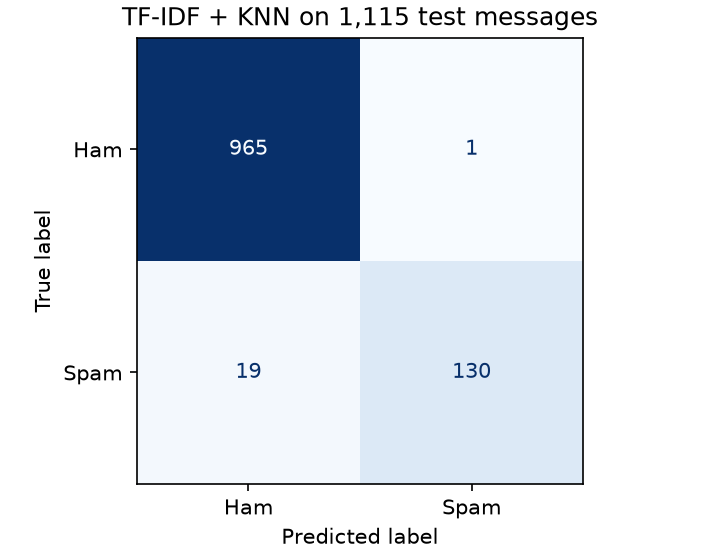

In [3]:
start = perf_counter()
part_a_pred = part_a_search.predict(X_test)
part_a_predict_seconds = perf_counter() - start

part_a_precision, part_a_recall, part_a_f1, _ = precision_recall_fscore_support(
    y_test, part_a_pred, average="binary", pos_label=1, zero_division=0,
)
part_a_matrix = confusion_matrix(y_test, part_a_pred, labels=[0, 1])
part_a_results = pd.DataFrame([{
    "Representation": "TF-IDF unigrams",
    "Dimensions": len(part_a_search.best_estimator_.named_steps["tfidf"].vocabulary_),
    "Best k": part_a_search.best_params_["knn__n_neighbors"],
    "Test accuracy": accuracy_score(y_test, part_a_pred),
    "Spam precision": part_a_precision,
    "Spam recall": part_a_recall,
    "Spam F1": part_a_f1,
    "CV + fit (seconds)": part_a_fit_seconds,
    "Test prediction (seconds)": part_a_predict_seconds,
}])
print(part_a_results.T.to_string(header=False, float_format="{:.4f}".format))

fig, ax = plt.subplots(figsize=(4.8, 3.7), layout="constrained")
ConfusionMatrixDisplay(part_a_matrix, display_labels=["Ham", "Spam"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_title(f"TF-IDF + KNN on {len(y_test):,} test messages")
plt.show()

## Export test predictions

`test_row` is the row number in the shared `test.csv`, counting the first message as 1.

In [4]:
part_a_predictions = test_df[["label", "text"]].copy()
part_a_predictions.insert(0, "test_row", range(1, len(part_a_predictions) + 1))
part_a_predictions["predicted_label"] = part_a_pred
part_a_predictions.to_csv("PartA_Test_Predictions.csv", index=False, encoding="utf-8")
print(f"Saved {len(part_a_predictions):,} predictions to PartA_Test_Predictions.csv")

part_a_text_overlap = int(X_test.isin(X_train).sum())
print(f"Test messages with identical text in training: {part_a_text_overlap:,}")

Saved 1,115 predictions to PartA_Test_Predictions.csv
Test messages with identical text in training: 129


## Interpretation

The model picked up recurring promotional language. Of the 130 spam messages it correctly flagged, 34 contained “free” and 37 contained at least one of “win,” “won,” “winner,” or “prize.” Some also contained long strings of digits or parts of URLs. A single message can contain several of these patterns.

The only false positive was a personal message at test row 683. It shared words such as “bloke” and “girl” with its closest training message, which was labeled as spam. This example shows how unigram features can make messages with different purposes appear similar when they share words.

We evaluated all 1,115 messages in the shared test set. Of these, 129 had text identical to a training message. This overlap may make the scores higher than they would be for entirely new messages.